# Notebook_D (Sinh viên B): kiểm tra chéo kết quả RQ2–RQ3 của Notebook_B trên WOMD v1.2

Notebook này **không tạo kết quả chính mới**. Nó đọc đúng bảng mà Notebook_B dùng: `data/processed/feat_core_origin10.parquet` (mỗi xe một dòng tại t = 1.0 s, 8 biến chung cho 3 s và 8 s), qua `manifest.json` của Notebook_A, rồi kiểm tra lại các con số của B bằng code viết độc lập.

- **Tái lập** (phải ra đúng số của B): cách chia, ba mốc vật lý, mô hình được chọn, MAE theo trạng thái chuyển động, conformal, ngưỡng hard case.
- **Độ nhạy** (số được phép khác, kết luận phải giữ): mô hình với tham số mặc định, 5-fold theo cảnh trên toàn bộ xe, conformal qua 5 cách chia calibration khác, bộ cảnh báo bằng logistic regression, permutation importance thay cho SHAP.

Mọi bảng và hình lưu ở `report/D/` để không ghi đè file của B. Bảng tổng hợp: `report/D/table_crosscheck_B.csv`.

**Theo file góp ý:** 3 s và 8 s dùng chung dòng và 8 biến (1a); bỏ Chronos (2.15); có mốc giữ nguyên gia tốc và CTRV (3.4); khoảng tin cậy bootstrap theo cảnh (3.2); tách xe đứng yên và đang chạy (3.3, 3.6); so bộ cảnh báo với quy tắc tốc độ (5.6). **Theo file hướng dẫn trực quan hoá:** hình rộng 4.8 in, chữ 8 pt, không tiêu đề trong hình, nhãn (a)/(b), một màu nhấn.

In [1]:
# CONFIG: cross-check of Notebook B on the WOMD v1.2 step-10 table
TOPIC = "Dự đoán quỹ đạo xe nhẹ có bất định conformal trên Waymo Open Motion Dataset"
GROUP = "Nhóm 7"
WOMD_SOURCE = {"name": "Waymo Open Motion Dataset v1.2", "url": "https://waymo.com/open/data/motion/", "license": "Waymo Open Dataset License"}
OUT, B_DIR = "report/D", "report"  # D writes only to report/D; Notebook B's tables are read from report/
UNIT_COL = "unit"
HORIZONS = {"3s": 3.0, "8s": 8.0}
TARGET = {"3s": "y_disp_3s", "8s": "y_disp_8s"}
MOTION_VIEW = ["speed", "dspeed_10step"]  # motion-only feature view for the ablation, same at both horizons
SPLIT_SEED, TEST_FRAC, CAL_FRAC, ALPHA = 42, 0.30, 0.25, 0.10  # must equal Notebook B
EVENT_QUANTILE, STOP_SPEED = 0.90, 0.5
SEEDS = [0, 1, 2, 3, 4]
N_BOOT = 2000
TOL = 1e-3  # relative tolerance: same data, split and seed; refitted tree models can differ in the 4th digit across library versions
print("Topic:", TOPIC)
print("Group:", GROUP)
print("Dataset:", WOMD_SOURCE["name"])
def close(d, b, tol=TOL):
    return np.all(np.abs(np.asarray(d, float) - np.asarray(b, float)) <= tol * np.maximum(1, np.abs(np.asarray(b, float))))

Topic: Dự đoán quỹ đạo xe nhẹ có bất định conformal trên Waymo Open Motion Dataset
Group: Nhóm 7
Dataset: Waymo Open Motion Dataset v1.2


In [2]:
# AI Audit Log helper: every prompt that changed your work is one row (2 minutes per entry, 3-5 per week)
import pandas as pd, os, datetime as dt
os.makedirs("report", exist_ok=True)
AUDIT_PATH = "report/ai_audit_log.csv"
def audit(step, prompt, tool, ai_output_summary, verified_how, decision, hallucination=False):
    """Append one entry. decision: what you kept / changed / rejected. hallucination=True if the AI answer was wrong and you caught it."""
    row = {
        "date": dt.date.today().isoformat(),
        "group": GROUP,
        "step": step,
        "prompt": prompt[:500],
        "tool": tool,
        "ai_output": ai_output_summary[:500],
        "verified_how": verified_how[:300],
        "decision": decision[:300],
        "hallucination": int(hallucination),
    }
    df = pd.DataFrame([row])
    df.to_csv(AUDIT_PATH, mode="a", header=not os.path.exists(AUDIT_PATH), index=False)
    print("audit entry saved:", step)
# example (delete after reading): audit("Step 2", "Given columns ... how to treat gaps longer than 3 steps?", "Claude", "suggested interpolate(limit=3) then drop", "checked share of gaps > 3 in Q4 below", "kept limit=3, dropped 1.2% rows")

## Hướng dẫn hỏi AI

Mỗi prompt làm thay đổi code/kết luận phải được kiểm tra trên dữ liệu thật trước khi dùng. Khi ghi Audit Log, ghi rõ:
**prompt → đề xuất của AI → cách tự kiểm tra → quyết định cuối cùng**.

Các kiểm tra quan trọng cho Notebook_D:
- dùng **đúng bảng, đúng cách chia và đúng seed** của Notebook_B; nếu số tái lập lệch thì dừng lại tìm nguyên nhân, không chỉnh số cho khớp;
- 3 s và 8 s dùng cùng dòng và cùng 8 biến (góp ý 1a);
- không biến nào là target hoặc thông tin tương lai;
- benchmark gồm ba mốc vật lý (giữ nguyên tốc độ, giữ nguyên gia tốc, CTRV) và các mô hình bảng; không dùng Chronos;
- ablation so sánh **hai feature view trong cùng WOMD v1.2**, không gọi là hai nguồn dữ liệu.

## Bước 0: nhận bàn giao và kiểm tra

Đọc `manifest.json`, so MD5 `origin_md5` của bảng step 10, kiểm tra schema và nạp bảng. Đọc các bảng kết quả của Notebook_B trong `report/` để so ở các bước sau; nếu thiếu thì chạy Notebook_B trước.

In [3]:
# Step 0: imports, paper figure style (same as Notebooks A-C), handover check and Notebook B outputs
import os, sys, json, hashlib, warnings, time, pickle, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import make_scorer, mean_absolute_error as MAE, mean_squared_error as MSE
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
np.random.seed(42)
os.makedirs(OUT, exist_ok=True)
FIG_W = 4.8  # LNCS text width in inches: figures are drawn at print size, so 8 pt stays 8 pt
C_TEXT, C_BASE, C_MID, C_ACCENT, C_GREY = "#1F3B57", "#9CC9E8", "#4F8FC0", "#FF7F66", "#AEB9C4"
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "text.color": C_TEXT,
        "axes.labelcolor": C_TEXT,
        "axes.edgecolor": C_TEXT,
        "xtick.color": C_TEXT,
        "ytick.color": C_TEXT,
        "axes.linewidth": 0.6,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.grid": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.dpi": 300,
        "pdf.fonttype": 42,
    }
)
NICE = {
    "speed": "Current speed",
    "acc": "Acceleration",
    "yaw_rate": "Yaw rate",
    "dspeed_10step": "Speed change over 1 s",
    "acc_ma1s": "Mean acceleration over 1 s",
    "yaw_ma1s": "Mean yaw rate over 1 s",
    "length": "Vehicle length",
    "n_agents": "Agents in scene",
}
def panel(ax, lab):
    ax.set_title(lab, loc="left", fontsize=8, pad=3)  # panel label only; the explanation belongs in the caption
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png")
    fig.savefig(f"{OUT}/{name}.pdf")
    plt.show()
    plt.close(fig)
    print(f"saved {OUT}/{name}.png")
man = json.load(open("data/processed/manifest.json", encoding="utf-8"))
path = man["model_table"]
md5_now = hashlib.md5(open(path, "rb").read()).hexdigest()
assert md5_now == man["origin_md5"], "step-10 table differs from Notebook A handoff"
core = pd.read_parquet(path)
X_COLS = man["origin_feature_cols"]
assert len(X_COLS) == 8 and (core["step"] == man["origin_step"]).all() and not core.duplicated(UNIT_COL).any()
assert core[X_COLS + list(TARGET.values())].notna().all().all(), "missing feature or target at the forecast origin"
assert not any(c.startswith("y_") for c in X_COLS), "target column used as a feature"
B_FILES = ["table_split", "table_tuning", "table_main_results", "table_motion_state", "table_conformal", "table_warning", "table_shap"]
missing = [f for f in B_FILES if not os.path.exists(f"{B_DIR}/{f}.csv")]
assert not missing, f"run Notebook B first, missing: {missing}"
B = {f.replace("table_", ""): pd.read_csv(f"{B_DIR}/{f}.csv") for f in B_FILES}
print("handover OK | md5:", md5_now)
print(
    f"rows={len(core)} | vehicles={core[UNIT_COL].nunique()} | scenarios={core['scenario'].nunique()} | "
    f"stationary share={(core['motion_state'] == 'stationary').mean():.3f}"
)
print("features:", [NICE[c] for c in X_COLS])
print("Python", platform.python_version(), "| Notebook B tables read:", len(B))

handover OK | md5: 22b48a9caf7d9f85eb7e24f6edd1caab
rows=1172 | vehicles=1172 | scenarios=1051 | stationary share=0.689
features: ['Current speed', 'Acceleration', 'Yaw rate', 'Speed change over 1 s', 'Mean acceleration over 1 s', 'Mean yaw rate over 1 s', 'Vehicle length', 'Agents in scene']
Python 3.11.16 | Notebook B tables read: 7


## Bước 4: chia theo cảnh và ba mốc vật lý

**Cách chia:** giữ 30% số cảnh làm test, **một lần chia dùng chung cho 3 s và 8 s**, cùng hàm và cùng seed với Notebook_B (góp ý 1a). Số dòng, xe và cảnh của mỗi phần phải trùng `table_split.csv` của B.

**Mốc vật lý** (góp ý 3.4) được viết lại ở dạng công thức khác với B rồi so số:
- giữ nguyên tốc độ: `v × h`;
- giữ nguyên gia tốc: chạy với gia tốc trung bình 1 s cho đến khi dừng hẳn (nếu đang phanh);
- CTRV: dây cung của cung tròn với yaw rate trung bình 1 s, viết bằng `sinc`.

In [4]:
# Step 4a: one usable table for both horizons (docx 1a): same rows and the same 8 predictors at 3 s and 8 s
for h, sec in HORIZONS.items():
    print(f"{h} | target valid={core[TARGET[h]].notna().sum():,} | usable={len(core):,} | features={len(X_COLS)}")
print(X_COLS)

3s | target valid=1,172 | usable=1,172 | features=8
8s | target valid=1,172 | usable=1,172 | features=8
['speed', 'acc', 'yaw_rate', 'dspeed_10step', 'acc_ma1s', 'yaw_ma1s', 'length', 'n_agents']


In [5]:
# Step 4b: the same 30% scenario-disjoint split as Notebook B (same seed), checked against B's table_split.csv
def scenario_split(frame, seed=SPLIT_SEED, test_frac=TEST_FRAC):
    scenarios = np.sort(frame["scenario"].unique())
    test_scenarios = np.random.RandomState(seed).choice(scenarios, int(np.ceil(len(scenarios) * test_frac)), replace=False)
    is_test = frame["scenario"].isin(test_scenarios)
    return frame[~is_test].copy(), frame[is_test].copy()
train, test = scenario_split(core)
assert set(train["scenario"]).isdisjoint(set(test["scenario"])) and set(train[UNIT_COL]).isdisjoint(set(test[UNIT_COL]))
split_tab = pd.DataFrame(
    [
        {
            "part": n,
            "rows": len(d),
            "vehicles": d[UNIT_COL].nunique(),
            "scenarios": d["scenario"].nunique(),
            "stationary_share": (d["motion_state"] == "stationary").mean(),
        }
        for n, d in [("train", train), ("test", test)]
    ]
)
cols = ["rows", "vehicles", "scenarios", "stationary_share"]
same_split = np.allclose(split_tab[cols].to_numpy(float), B["split"][cols].to_numpy(float))
assert same_split, "split differs from Notebook B"
split_tab.to_csv(f"{OUT}/table_split.csv", index=False)
display(split_tab.round(3))
print("split identical to Notebook B:", same_split)
Xtr, Xte = train[X_COLS], test[X_COLS]
COV_TOL = 1.01 / len(test)  # coverage may differ by at most one test vehicle when a refitted model differs in the 4th digit
y_tr, y_te = train[TARGET["3s"]], test[TARGET["3s"]]

,part,rows,vehicles,scenarios,stationary_share
0,train,817,817,735,0.704
1,test,355,355,316,0.656


split identical to Notebook B: True


In [6]:
# Step 4c: physical baselines re-implemented in a different closed form, then compared with Notebook B (docx 3.4)
def physical_baselines(df, h):
    v, a, w = (df[c].to_numpy(float) for c in ["speed", "acc_ma1s", "yaw_ma1s"])
    t_move = np.where(a < 0, np.minimum(h, v / np.maximum(-a, 1e-9)), h)  # constant acceleration until the vehicle stops
    ca = v * t_move + 0.5 * a * t_move**2
    ctrv = v * h * np.abs(np.sinc(w * h / (2 * np.pi)))  # chord of the arc: 2v/|w|*|sin(wh/2)| written with sinc
    return {"Constant velocity": np.clip(v * h, 0, None), "Constant acceleration": np.clip(ca, 0, None), "CTRV": np.clip(ctrv, 0, None)}
PHYS = {h: physical_baselines(test, sec) for h, sec in HORIZONS.items()}
base_rows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    for name, p in PHYS[h].items():
        b = B["main_results"].query("horizon == @h and method == @name").iloc[0]
        base_rows.append({"horizon": h, "baseline": name, "MAE_D": MAE(y, p), "MAE_B": b.MAE, "RMSE_D": MSE(y, p) ** 0.5, "RMSE_B": b.RMSE})
baseline_table = pd.DataFrame(base_rows)
baseline_table["abs_diff"] = (baseline_table["MAE_D"] - baseline_table["MAE_B"]).abs()
baseline_table.to_csv(f"{OUT}/table_rq2_baseline.csv", index=False)
display(baseline_table.round(4))
assert (baseline_table["abs_diff"] < 1e-4).all(), "physical baselines differ from Notebook B"

,horizon,baseline,MAE_D,MAE_B,RMSE_D,RMSE_B,abs_diff
0,3s,Constant velocity,1.3701,1.3701,2.8442,2.8442,0.0
1,3s,Constant acceleration,0.9667,0.9667,2.4128,2.4128,0.0
2,3s,CTRV,1.3810,1.3810,2.8612,2.8612,0.0
3,8s,Constant velocity,8.7551,8.7551,17.6919,17.6919,0.0
4,8s,Constant acceleration,7.9259,7.9259,19.3087,19.3087,0.0
5,8s,CTRV,8.8991,8.8991,18.0406,18.0406,0.0


## Chỉ số đánh giá

Bảng dùng **MAE** và **RMSE** (m). Mức giảm so với mốc: **ΔCV = 1 − MAE(mô hình) / MAE(giữ nguyên tốc độ)** và **ΔCA = 1 − MAE(mô hình) / MAE(giữ nguyên gia tốc)**, giá trị dương nghĩa là tốt hơn mốc.

Khoảng tin cậy 95% lấy bằng bootstrap theo cảnh (2,000 lần) với seed khác Notebook_B, nên cận khoảng có thể lệch B một chút; giá trị điểm phải trùng. Không dùng sMAPE vì nhiều xe có quãng đường bằng 0. RQ3 luôn báo coverage cùng độ rộng khoảng.

In [7]:
# Metrics and an independent scenario-cluster bootstrap (different seed from Notebook B)
def scenario_bootstrap(scen, n=N_BOOT, seed=7):
    groups = list(pd.Series(np.arange(len(scen))).groupby(np.asarray(scen)).indices.values())
    rng = np.random.default_rng(seed)
    return [np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))]) for _ in range(n)]
BOOT = scenario_bootstrap(test["scenario"].to_numpy())
def ci(fn):
    return np.quantile([fn(i) for i in BOOT], [0.025, 0.975])
def metrics(y, p, p_cv, p_ca):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e, e_cv, e_ca = np.abs(y - p), np.abs(y - p_cv), np.abs(y - p_ca)
    return {
        "MAE": e.mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "dCV_pct": 100 * (1 - e.mean() / e_cv.mean()),
        "dCA_pct": 100 * (1 - e.mean() / e_ca.mean()),
    }
def verdict(lo, hi):
    return "better than CA" if lo > 0 else ("worse than CA" if hi < 0 else "no clear difference")
print(metrics(test["y_disp_3s"], PHYS["3s"]["Constant acceleration"], PHYS["3s"]["Constant velocity"], PHYS["3s"]["Constant acceleration"]))

{'MAE': 0.9666577916819997, 'RMSE': 2.4128257142739313, 'dCV_pct': 29.448640461190536, 'dCA_pct': 0.0}


## Bước 6a: benchmark với tham số mặc định (độ nhạy theo tinh chỉnh)

Notebook_B tinh chỉnh từng họ mô hình trên train. Ở đây chạy lại 5 mô hình (Ridge, Random Forest, HistGradientBoosting, LightGBM, XGBoost) với **tham số mặc định cố định**, trên cùng cách chia; Random Forest, LightGBM và XGBoost chạy 5 seed.

Câu hỏi: kết luận chính của B (ở 3 s mô hình bảng chưa hơn mốc giữ nguyên gia tốc; ở 8 s mô hình bảng hơn mốc giữ nguyên tốc độ) có phụ thuộc vào việc tinh chỉnh hay không.

In [8]:
# Step 6a-1: model zoo with fixed default settings (names match Notebook B)
def make_models(seed):
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=seed),
        "LightGBM": LGBMRegressor(
            n_estimators=800, learning_rate=0.03, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=seed, verbose=-1
        ),
        "XGBoost": XGBRegressor(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            n_jobs=-1,
            random_state=seed,
            verbosity=0,
        ),
    }
STOCHASTIC_MODELS = {"Random Forest", "LightGBM", "XGBoost"}
print("models:", list(make_models(0)))

models: ['Ridge', 'Random Forest', 'HistGradientBoosting', 'LightGBM', 'XGBoost']


In [9]:
# Step 6a-2: default-setting benchmark at both horizons, physical baselines included
results, PRED_DEF = [], {}
for h in HORIZONS:
    ytr, yte = train[TARGET[h]], test[TARGET[h]].to_numpy()
    PRED_DEF[h] = dict(PHYS[h])
    for name, p in PHYS[h].items():
        results.append(
            {
                "model": name,
                "horizon": h,
                "seed": 0,
                "negative_pred_share_raw": 0.0,
                **metrics(yte, p, PHYS[h]["Constant velocity"], PHYS[h]["Constant acceleration"]),
            }
        )
    for seed in SEEDS:
        for name, model in make_models(seed).items():
            if name not in STOCHASTIC_MODELS and seed != SEEDS[0]:
                continue  # deterministic models need one run
            raw = model.fit(Xtr, ytr).predict(Xte)
            pred = np.clip(raw, 0.0, None)  # displacement cannot be negative
            results.append(
                {
                    "model": name,
                    "horizon": h,
                    "seed": seed,
                    "negative_pred_share_raw": float((raw < 0).mean()),
                    **metrics(yte, pred, PHYS[h]["Constant velocity"], PHYS[h]["Constant acceleration"]),
                }
            )
            if seed == SEEDS[0]:
                PRED_DEF[h][name] = pred
res = pd.DataFrame(results)
res.to_csv(f"{OUT}/table_rq2_raw.csv", index=False)
summary = res.groupby(["horizon", "model"])[["MAE", "RMSE", "dCV_pct", "dCA_pct", "negative_pred_share_raw"]].agg(["mean", "std"]).round(4)
summary.to_csv(f"{OUT}/table_rq2_summary.csv")
display(summary)

MAE             RMSE          dCV_pct  \
                                 mean     std     mean     std     mean   
horizon model                                                             
3s      CTRV                   1.3810     NaN   2.8612     NaN  -0.7932   
        Constant acceleration  0.9667     NaN   2.4128     NaN  29.4486   
        Constant velocity      1.3701     NaN   2.8442     NaN   0.0000   
        HistGradientBoosting   1.0869     NaN   2.1479     NaN  20.6699   
        LightGBM               1.2231  0.0225   2.4116  0.0199  10.7289   
        Random Forest          1.0224  0.0051   2.1230  0.0124  25.3807   
        Ridge                  1.1443     NaN   2.3958     NaN  16.4870   
        XGBoost                1.3719  0.0594   2.6653  0.1425  -0.1312   
8s      CTRV                   8.8991     NaN  18.0406     NaN  -1.6458   
        Constant acceleration  7.9259     NaN  19.3087     NaN   9.4712   
        Constant velocity      8.7551     NaN  17.6919     NaN   0.0000   
        HistGradientBoosting   7.2010     NaN  13.9877     NaN  17.7505   
        LightGBM               7.4232  0.0560  14.3517  0.0915  15.2125   
        Random Forest          7.0852  0.0295  13.5537  0.0356  19.0728   
        Ridge                  9.1036     NaN  15.5407     NaN  -3.9812   
        XGBoost                7.4462  0.1184  14.0007  0.1631  14.9492   

                                       dCA_pct          \
                                  std     mean     std   
horizon model                                            
3s      CTRV                      NaN -42.8649     NaN   
        Constant acceleration     NaN   0.0000     NaN   
        Constant velocity         NaN -41.7407     NaN   
        HistGradientBoosting      NaN -12.4430     NaN   
        LightGBM               1.6455 -26.5335  2.3323   
        Random Forest          0.3745  -5.7659  0.5308   
        Ridge                     NaN -18.3719     NaN   
        XGBoost                4.3329 -41.9266  6.1415   
8s      CTRV                      NaN -12.2800     NaN   
        Constant acceleration     NaN   0.0000     NaN   
        Constant velocity         NaN -10.4620     NaN   
        HistGradientBoosting      NaN   9.1455     NaN   
        LightGBM               0.6394   6.3420  0.7063   
        Random Forest          0.3370  10.6062  0.3723   
        Ridge                     NaN -14.8597     NaN   
        XGBoost                1.3525   6.0511  1.4940   

                              negative_pred_share_raw          
                                                 mean     std  
horizon model                                                  
3s      CTRV                                   0.0000     NaN  
        Constant acceleration                  0.0000     NaN  
        Constant velocity                      0.0000     NaN  
        HistGradientBoosting                   0.3155     NaN  
        LightGBM                               0.3290  0.0171  
        Random Forest                          0.0000  0.0000  
        Ridge                                  0.1493     NaN  
        XGBoost                                0.2868  0.0417  
8s      CTRV                                   0.0000     NaN  
        Constant acceleration                  0.0000     NaN  
        Constant velocity                      0.0000     NaN  
        HistGradientBoosting                   0.2761     NaN  
        LightGBM                               0.2845  0.0134  
        Random Forest                          0.0000  0.0000  
        Ridge                                  0.0873     NaN  
        XGBoost                                0.2834  0.0569

In [10]:
for h in HORIZONS:
    print(f"\n{h}")
    for name, pred in PRED_DEF[h].items():
        print(f"{name:22s}", "min =", round(float(pred.min()), 4), "| negative =", int((pred < 0).sum()))


3s
Constant velocity      min = 0.0 | negative = 0
Constant acceleration  min = 0.0 | negative = 0
CTRV                   min = 0.0 | negative = 0
Ridge                  min = 0.0 | negative = 0
Random Forest          min = 0.0 | negative = 0
HistGradientBoosting   min = 0.0 | negative = 0
LightGBM               min = 0.0 | negative = 0
XGBoost                min = 0.0 | negative = 0

8s
Constant velocity      min = 0.0 | negative = 0
Constant acceleration  min = 0.0 | negative = 0
CTRV                   min = 0.0 | negative = 0
Ridge                  min = 0.0 | negative = 0
Random Forest          min = 0.0 | negative = 0
HistGradientBoosting   min = 0.0 | negative = 0
LightGBM               min = 0.0 | negative = 0
XGBoost                min = 0.0 | negative = 0


In [11]:
# Step 6a-3: benchmark integrity note
assert "chronos" not in sys.modules, "Chronos must not be used (docx 2.15)"
print("Benchmark contains three physical baselines and five tabular models on the same test vehicles. Chronos was removed.")

Benchmark contains three physical baselines and five tabular models on the same test vehicles. Chronos was removed.


,horizon,method,kind,MAE_default,CI_low,CI_high,dCA_pct,dCA_CI_low,dCA_CI_high,MAE_B_tuned,B_selected
0,3s,Constant acceleration,physical baseline,0.967,0.765,1.212,0.000,0.000,0.000,0.967,False
1,3s,Random Forest,tabular model,1.026,0.833,1.235,-6.130,-29.032,13.887,1.036,False
2,3s,HistGradientBoosting,tabular model,1.087,0.890,1.284,-12.443,-37.082,8.321,1.019,False
3,3s,Ridge,tabular model,1.144,0.939,1.381,-18.372,-37.974,-3.837,1.141,True
4,3s,LightGBM,tabular model,1.246,1.028,1.472,-28.855,-56.070,-4.281,1.072,False
5,3s,XGBoost,tabular model,1.345,1.112,1.583,-39.132,-71.865,-13.936,1.039,False
6,3s,Constant velocity,physical baseline,1.370,1.107,1.650,-41.741,-76.786,-11.366,1.370,False
7,3s,CTRV,physical baseline,1.381,1.119,1.662,-42.865,-77.990,-12.299,1.381,False
8,8s,Random Forest,tabular model,7.088,5.882,8.310,10.570,-7.215,25.729,6.979,True
9,8s,HistGradientBoosting,tabular model,7.201,5.952,8.468,9.145,-9.066,24.027,7.316,False


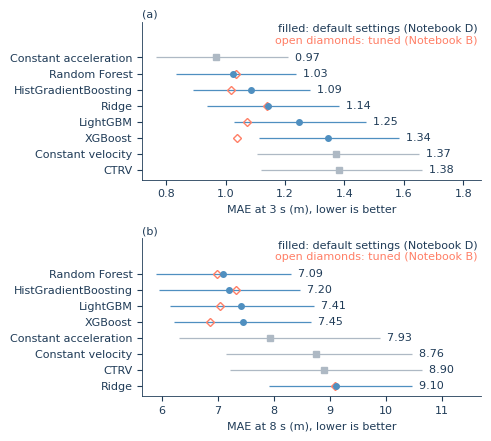

saved report/D/fig_rq2_models.png
3s: best default model Random Forest | MAE 1.026 | vs constant acceleration -6.1% (95% CI -29.0 to +13.9) -> no clear difference
8s: best default model Random Forest | MAE 7.088 | vs constant acceleration +10.6% (95% CI -7.2 to +25.7) -> no clear difference


In [12]:
# Step 6a-4: default settings vs Notebook B's tuned models, paired 95% CIs against constant acceleration
rows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    e_ca = np.abs(y - PHYS[h]["Constant acceleration"])
    for m, p in PRED_DEF[h].items():
        e = np.abs(y - p)
        lo, hi = ci(lambda i: e[i].mean())
        alo, ahi = ci(lambda i: 100 * (1 - e[i].mean() / e_ca[i].mean()))
        b = B["main_results"].query("horizon == @h and method == @m").iloc[0]
        rows.append(
            {
                "horizon": h,
                "method": m,
                "kind": "physical baseline" if m in PHYS[h] else "tabular model",
                "MAE_default": e.mean(),
                "CI_low": lo,
                "CI_high": hi,
                "dCA_pct": 100 * (1 - e.mean() / e_ca.mean()),
                "dCA_CI_low": alo,
                "dCA_CI_high": ahi,
                "MAE_B_tuned": b.MAE,
                "B_selected": bool(b.selected),
            }
        )
cmp_def = pd.DataFrame(rows).sort_values(["horizon", "MAE_default"]).reset_index(drop=True)
cmp_def.to_csv(f"{OUT}/table_rq2_default_vs_tuned.csv", index=False)
display(cmp_def.round(3))
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 4.3))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    r = cmp_def[cmp_def["horizon"] == h].sort_values("MAE_default", ascending=False).reset_index(drop=True)
    for yp, row in r.iterrows():
        base = row.kind == "physical baseline"
        ax.errorbar(
            row.MAE_default,
            yp,
            xerr=[[row.MAE_default - row.CI_low], [row.CI_high - row.MAE_default]],
            fmt="s" if base else "o",
            color=C_GREY if base else C_MID,
            ms=4,
            elinewidth=0.9,
            capsize=0,
        )
        if not base:
            ax.plot(row.MAE_B_tuned, yp, "D", mfc="none", mec=C_ACCENT, ms=4.5, mew=1.0)
        ax.text(row.CI_high, yp, f"  {row.MAE_default:.2f}", va="center")
    ax.text(0.99, len(r) + 0.75, "filled: default settings (Notebook D)", transform=ax.get_yaxis_transform(), ha="right", va="center")
    ax.text(0.99, len(r) + 0.05, "open diamonds: tuned (Notebook B)", transform=ax.get_yaxis_transform(), ha="right", va="center", color=C_ACCENT)
    ax.set_yticks(range(len(r)))
    ax.set_yticklabels(r["method"])
    lo_, hi_ = min(r["CI_low"].min(), r["MAE_B_tuned"].min()), r["CI_high"].max()
    ax.set_xlim(lo_ - 0.05 * (hi_ - lo_), hi_ + 0.22 * (hi_ - lo_))
    ax.set_ylim(-0.6, len(r) + 1.2)
    ax.set_xlabel(f"MAE at {h[0]} s (m), lower is better")
    panel(ax, lab)
fig.tight_layout(pad=0.4, h_pad=1.0)
save_fig(fig, "fig_rq2_models")
for h in HORIZONS:
    r = cmp_def[(cmp_def["horizon"] == h) & (cmp_def["kind"] == "tabular model")].iloc[0]
    print(
        f"{h}: best default model {r.method} | MAE {r.MAE_default:.3f} | vs constant acceleration {r.dCA_pct:+.1f}% "
        f"(95% CI {r.dCA_CI_low:+.1f} to {r.dCA_CI_high:+.1f}) -> {verdict(r.dCA_CI_low, r.dCA_CI_high)}"
    )

In [13]:
# Step 6a-5: rank of every method at 3 s and 8 s, default settings (Notebook D) next to tuned (Notebook B)
rank = cmp_def.assign(rank_default=cmp_def.groupby("horizon")["MAE_default"].rank(), rank_B_tuned=cmp_def.groupby("horizon")["MAE_B_tuned"].rank())
rank = rank.pivot(index="method", columns="horizon", values=["MAE_default", "MAE_B_tuned", "rank_default", "rank_B_tuned"]).sort_values(
    ("rank_B_tuned", "3s")
)
rank.to_csv(f"{OUT}/table_rq2_by_horizon.csv")
display(rank.round(3))

MAE_default        MAE_B_tuned        rank_default       \
horizon                        3s     8s          3s     8s           3s   8s   
method                                                                          
Constant acceleration       0.967  7.926       0.967  7.926          1.0  5.0   
HistGradientBoosting        1.087  7.201       1.019  7.316          3.0  2.0   
Random Forest               1.026  7.088       1.036  6.979          2.0  1.0   
XGBoost                     1.345  7.445       1.039  6.860          6.0  4.0   
LightGBM                    1.246  7.413       1.072  7.032          5.0  3.0   
Ridge                       1.144  9.104       1.141  9.096          4.0  8.0   
Constant velocity           1.370  8.755       1.370  8.755          7.0  6.0   
CTRV                        1.381  8.899       1.381  8.899          8.0  7.0   

                      rank_B_tuned       
horizon                         3s   8s  
method                                   
Constant acceleration          1.0  5.0  
HistGradientBoosting           2.0  4.0  
Random Forest                  3.0  2.0  
XGBoost                        4.0  1.0  
LightGBM                       5.0  3.0  
Ridge                          6.0  8.0  
Constant velocity              7.0  6.0  
CTRV                           8.0  7.0

In [14]:
# Step 6a-6: family choice with default settings and TRAIN-ONLY grouped CV, compared with Notebook B's tuned choice
mae_scorer = make_scorer(lambda y, p: MAE(y, np.clip(p, 0, None)), greater_is_better=False)
B_SELECTED = B["tuning"][B["tuning"]["selected"].astype(str) == "True"].set_index("horizon")["model"].to_dict()
fam_rows = []
for h in HORIZONS:
    for name, model in make_models(0).items():
        s = -cross_val_score(model, Xtr, train[TARGET[h]], groups=train["scenario"], cv=GroupKFold(n_splits=5), scoring=mae_scorer)
        fam_rows.append(
            {
                "horizon": h,
                "model": name,
                "CV_MAE_default": s.mean(),
                "CV_MAE_std": s.std(),
                "CV_MAE_B_tuned": B["tuning"].query("horizon == @h and model == @name")["cv_MAE"].iloc[0],
            }
        )
fam = pd.DataFrame(fam_rows).sort_values(["horizon", "CV_MAE_default"]).reset_index(drop=True)
fam.to_csv(f"{OUT}/table_rq2_family_selection_cv.csv", index=False)
display(fam.round(4))
D_SELECTED = fam.groupby("horizon")["model"].first().to_dict()
print("default-setting CV choice:", D_SELECTED, "| Notebook B tuned choice:", B_SELECTED)

,horizon,model,CV_MAE_default,CV_MAE_std,CV_MAE_B_tuned
0,3s,Ridge,1.0417,0.1355,1.0326
1,3s,Random Forest,1.1594,0.1790,1.0778
2,3s,HistGradientBoosting,1.2366,0.2202,1.1245
3,3s,LightGBM,1.3105,0.1950,1.1502
4,3s,XGBoost,1.4389,0.1797,1.0368
5,8s,Random Forest,6.7060,0.7402,6.5256
6,8s,HistGradientBoosting,7.2933,1.0771,6.8653
7,8s,XGBoost,7.4114,0.6643,6.7441
8,8s,LightGBM,7.5539,0.7915,6.9778
9,8s,Ridge,7.7910,0.3801,7.7659


default-setting CV choice: {'3s': 'Ridge', '8s': 'Random Forest'} | Notebook B tuned choice: {'3s': 'Ridge', '8s': 'Random Forest'}


### Tái lập mô hình được chọn của Notebook_B

Không tinh chỉnh lại. Đọc tham số tốt nhất từ `report/table_tuning.csv` của B, huấn luyện lại họ mà B đã chọn (seed 0) trên cùng tập train, rồi so MAE test với `table_main_results.csv`. Hai số phải trùng; nếu lệch thì dữ liệu, cách chia hoặc phiên bản thư viện đã khác.

In [15]:
# Step 6a-7: refit Notebook B's selected model from its saved parameters and reproduce its test numbers
def make_tuned(name, params, seed=0):
    p = dict(params)
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**{k.replace("ridge__", ""): v for k, v in p.items()}))
    if name == "Random Forest":
        return RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    if name == "HistGradientBoosting":
        return HistGradientBoostingRegressor(random_state=seed, **p)
    if name == "LightGBM":
        return LGBMRegressor(random_state=seed, verbose=-1, **p)
    if name == "XGBoost":
        return XGBRegressor(random_state=seed, n_jobs=-1, verbosity=0, **p)
    raise ValueError(name)
PARAMS = {(r.horizon, r.model): json.loads(r.best_params) for r in B["tuning"].itertuples()}
best_by_h, PRED_SEL, tuning_rows = {}, {}, []
for h in HORIZONS:
    name = B_SELECTED[h]
    best_by_h[h] = make_tuned(name, PARAMS[(h, name)]).fit(Xtr, train[TARGET[h]])
    PRED_SEL[h] = np.clip(best_by_h[h].predict(Xte), 0, None)
    b = B["main_results"].query("horizon == @h and method == @name").iloc[0]
    m = metrics(test[TARGET[h]], PRED_SEL[h], PHYS[h]["Constant velocity"], PHYS[h]["Constant acceleration"])
    tuning_rows.append(
        {
            "horizon": h,
            "model": name,
            "best_params": json.dumps(PARAMS[(h, name)]),
            "test_MAE_D": m["MAE"],
            "test_MAE_B": b.MAE,
            "dCV_D": m["dCV_pct"],
            "dCV_B": b.reduction_vs_CV_pct,
            "dCA_D": m["dCA_pct"],
            "dCA_B": b.reduction_vs_CA_pct,
        }
    )
tuned = pd.DataFrame(tuning_rows)
tuned["reproduced"] = [close(d, b) for d, b in zip(tuned["test_MAE_D"], tuned["test_MAE_B"])]
tuned.to_csv(f"{OUT}/table_rq2_tuning.csv", index=False)
display(tuned.drop(columns="best_params").round(4))
assert tuned["reproduced"].all(), "selected model does not reproduce Notebook B's test MAE"

,horizon,model,test_MAE_D,test_MAE_B,dCV_D,dCV_B,dCA_D,dCA_B,reproduced
0,3s,Ridge,1.1408,1.1408,16.7413,16.7413,-18.0115,-18.0115,True
1,8s,Random Forest,6.9795,6.9795,20.2805,20.2805,11.9402,11.9402,True


method                 Ridge  Constant acceleration  Constant velocity  \
horizon density_group                                                    
3s      ≤35 agents     1.613                  1.428              2.002   
        36–59 agents   1.337                  1.092              1.486   
        >59 agents     0.543                  0.443              0.703   
8s      ≤35 agents       NaN                 12.649             14.252   
        36–59 agents     NaN                  8.380              8.672   
        >59 agents       NaN                  3.313              3.940   

method                 Random Forest  
horizon density_group                 
3s      ≤35 agents               NaN  
        36–59 agents             NaN  
        >59 agents               NaN  
8s      ≤35 agents            11.411  
        36–59 agents           6.309  
        >59 agents             3.644

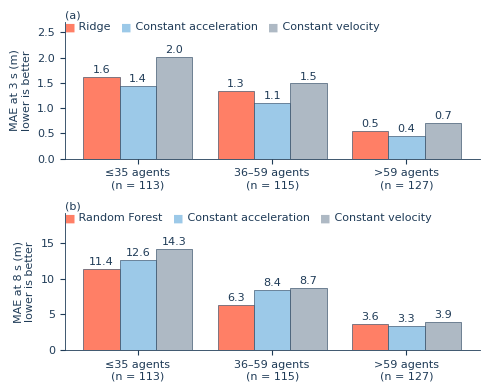

saved report/D/fig_rq2_error_by_density.png


In [16]:
# Step 6a-8: MAE by scene density (train tertiles of agents in scene) for the selected model and two physical baselines
q1, q2 = np.quantile(train["n_agents"], [1 / 3, 2 / 3]).round()
dens_lab = [f"≤{q1:.0f} agents", f"{q1 + 1:.0f}–{q2:.0f} agents", f">{q2:.0f} agents"]
dens = pd.cut(test["n_agents"], [-np.inf, q1, q2, np.inf], labels=dens_lab).astype(str).to_numpy()
drows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    for g in dens_lab:
        m = dens == g
        for meth, p in [
            (B_SELECTED[h], PRED_SEL[h]),
            ("Constant acceleration", PHYS[h]["Constant acceleration"]),
            ("Constant velocity", PHYS[h]["Constant velocity"]),
        ]:
            drows.append({"horizon": h, "density_group": g, "n_vehicles": int(m.sum()), "method": meth, "MAE": MAE(y[m], p[m])})
density_table = pd.DataFrame(drows)
density_table.to_csv(f"{OUT}/table_rq2_error_by_density.csv", index=False)
display(density_table.pivot_table(index=["horizon", "density_group"], columns="method", values="MAE", sort=False).round(3))
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 3.8))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    d = density_table[density_table["horizon"] == h]
    meths = [B_SELECTED[h], "Constant acceleration", "Constant velocity"]
    x = np.arange(len(dens_lab))
    for k, (meth, col) in enumerate(zip(meths, [C_ACCENT, C_BASE, C_GREY])):
        v = d[d["method"] == meth]["MAE"].to_numpy()
        bars = ax.bar(x + (k - 1) * 0.27, v, 0.27, color=col, edgecolor=C_TEXT, linewidth=0.4)
        ax.bar_label(bars, labels=[f"{t:.1f}" for t in v], padding=1.5)
    t = None
    for meth, col in zip(meths, [C_ACCENT, C_BASE, C_GREY]):  # colour key written as a line of text, no legend box
        sq = ax.annotate(
            "■", (0, 1) if t is None else (1, 0), xycoords="axes fraction" if t is None else t, va="top" if t is None else "bottom", color=col
        )
        t = ax.annotate(f" {meth}   ", (1, 0), xycoords=sq, va="bottom")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{g}\n(n = {n})" for g, n in zip(dens_lab, d.groupby("density_group", sort=False)["n_vehicles"].first())])
    ax.set_ylim(0, d["MAE"].max() * 1.35)
    ax.set_ylabel(f"MAE at {h[0]} s (m)\nlower is better")
    panel(ax, lab)
fig.tight_layout(pad=0.4, h_pad=1.0)
save_fig(fig, "fig_rq2_error_by_density")

## RQ2 sâu hơn: 5-fold theo cảnh trên toàn bộ xe

Bản cũ dùng trajectory-progress backtest và unseen-unit trên bảng nhiều step mỗi xe. Sau góp ý 1a, mỗi xe chỉ còn **một dòng tại t = 1.0 s**, nên hai kiểm tra đó không còn áp dụng (mọi xe test đã là xe và cảnh chưa thấy).

Thay vào đó: **GroupKFold 5 phần theo cảnh trên toàn bộ 1,172 xe**, mỗi xe được dự báo đúng một lần khi nằm trong phần test. Kết quả cho biết kết luận của B có đứng vững khi không phụ thuộc vào một lần chia 70/30 hay không (bổ sung cho 5 cách chia trong `table_split_robustness.csv` của B). Tham số mô hình lấy từ B, đã chọn trên train của B, nên kết quả ở đây hơi lạc quan một chút.

In [17]:
# RQ2-1: 5-fold scenario-grouped cross-validation over all vehicles, Notebook B's tuned parameters fixed
fold_rows = []
for h, sec in HORIZONS.items():
    name, y_all = B_SELECTED[h], core[TARGET[h]].to_numpy()
    for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(core, groups=core["scenario"])):
        p = np.clip(make_tuned(name, PARAMS[(h, name)]).fit(core.iloc[a][X_COLS], y_all[a]).predict(core.iloc[b][X_COLS]), 0, None)
        ph = physical_baselines(core.iloc[b], sec)
        fold_rows.append(
            {
                "horizon": h,
                "fold": k,
                "model": name,
                "test_vehicles": len(b),
                **metrics(y_all[b], p, ph["Constant velocity"], ph["Constant acceleration"]),
            }
        )
folds = pd.DataFrame(fold_rows)
folds.to_csv(f"{OUT}/table_rq2_folds.csv", index=False)
display(folds.round(3))
fold_sum = folds.groupby("horizon")[["MAE", "dCV_pct", "dCA_pct"]].agg(["mean", "std", "min", "max"]).round(2)
display(fold_sum)
for h in HORIZONS:
    f = folds[folds["horizon"] == h]
    print(
        f"{h}: {B_SELECTED[h]} beats constant acceleration in {(f['dCA_pct'] > 0).sum()} of 5 folds and constant velocity in {(f['dCV_pct'] > 0).sum()} of 5 folds"
    )

,horizon,fold,model,test_vehicles,MAE,RMSE,dCV_pct,dCA_pct
0,3s,0,Ridge,235,0.833,1.867,9.881,-30.854
1,3s,1,Ridge,235,1.048,1.879,26.364,-20.449
2,3s,2,Ridge,234,1.120,2.288,22.907,-17.254
3,3s,3,Ridge,234,1.087,1.943,25.553,-16.803
4,3s,4,Ridge,234,1.291,2.827,13.903,-5.532
5,8s,0,Random Forest,235,5.365,10.859,14.699,0.903
6,8s,1,Random Forest,235,6.038,11.744,28.334,5.372
7,8s,2,Random Forest,234,6.624,14.127,23.299,2.479
8,8s,3,Random Forest,234,7.017,12.731,23.182,7.249
9,8s,4,Random Forest,234,8.528,16.161,6.633,0.589


MAE                   dCV_pct                    dCA_pct        \
         mean   std   min   max    mean   std   min    max    mean   std   
horizon                                                                    
3s       1.08  0.16  0.83  1.29   19.72  7.40  9.88  26.36  -18.18  9.06   
8s       6.71  1.19  5.37  8.53   19.23  8.58  6.63  28.33    3.32  2.90   

                      
           min   max  
horizon               
3s      -30.85 -5.53  
8s        0.59  7.25

3s: Ridge beats constant acceleration in 0 of 5 folds and constant velocity in 5 of 5 folds
8s: Random Forest beats constant acceleration in 5 of 5 folds and constant velocity in 5 of 5 folds


In [18]:
# RQ2-3: per-vehicle absolute error distribution by motion state (not only the mean); MAE must match Notebook B
qrows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    for state in ["stationary", "moving"]:
        m = (test["motion_state"] == state).to_numpy()
        for meth, p in [
            (B_SELECTED[h], PRED_SEL[h]),
            ("Constant acceleration", PHYS[h]["Constant acceleration"]),
            ("Constant velocity", PHYS[h]["Constant velocity"]),
        ]:
            e = np.abs(y[m] - p[m])
            qrows.append(
                {
                    "horizon": h,
                    "motion_state": state,
                    "method": meth,
                    "n_vehicles": int(m.sum()),
                    "MAE": e.mean(),
                    "median": np.median(e),
                    "p75": np.quantile(e, 0.75),
                    "p90": np.quantile(e, 0.90),
                    "max": e.max(),
                }
            )
pu = pd.DataFrame(qrows)
pu.to_csv(f"{OUT}/table_rq2_per_vehicle_quantiles.csv", index=False)
display(pu.round(3))
chk_motion = pu.merge(B["motion_state"], on=["horizon", "motion_state", "method"], suffixes=("", "_B"))
assert len(chk_motion) == len(pu) and close(chk_motion["MAE"], chk_motion["MAE_B"]), "MAE by motion state differs from Notebook B"
print("MAE by motion state matches Notebook B in", len(chk_motion), "rows")

,horizon,motion_state,method,n_vehicles,MAE,median,p75,p90,max
0,3s,stationary,Ridge,233,0.336,0.212,0.337,0.502,8.320
1,3s,stationary,Constant acceleration,233,0.167,0.000,0.000,0.089,8.580
2,3s,stationary,Constant velocity,233,0.163,0.000,0.000,0.238,8.251
3,3s,moving,Ridge,122,2.679,1.907,3.761,5.594,21.380
4,3s,moving,Constant acceleration,122,2.494,1.737,3.420,5.450,25.110
5,3s,moving,Constant velocity,122,3.676,2.753,5.865,7.855,12.269
6,8s,stationary,Random Forest,233,1.731,0.000,0.000,6.216,41.908
7,8s,stationary,Constant acceleration,233,2.023,0.000,0.000,1.740,54.693
8,8s,stationary,Constant velocity,233,2.029,0.000,0.000,1.114,53.706
9,8s,moving,Random Forest,122,17.003,13.313,24.579,36.313,70.220


MAE by motion state matches Notebook B in 12 rows


## Bước 6b (RQ3): kiểm tra chéo bất định và cảnh báo

1. split conformal 90% ở cả 3 s và 8 s, **cùng cách chia proper/calibration với B**, viết lại bằng thứ tự thống kê (phần dư nhỏ thứ k, k = ⌈(n+1)(1−α)⌉); thêm **5 cách chia calibration khác** để xem coverage dao động bao nhiêu;
2. conformal theo trạng thái (đứng yên / đang chạy), báo coverage và độ rộng cắt tại 0 và chưa cắt (góp ý 3.6, 5.1);
3. ngưỡng hard case từ phần dư out-of-fold trên train, cùng định nghĩa với B;
4. bộ cảnh báo thứ hai bằng **logistic regression**, so với LightGBM của B và quy tắc tốc độ (góp ý 3.7, 5.6);
5. chẩn đoán theo trạng thái chuyển động và mật độ cảnh;
6. ablation giữa hai feature view của cùng WOMD v1.2.

Phần Chronos đã bỏ theo góp ý (mục 2, dòng 15).

In [19]:
# RQ3-1: split conformal re-implemented as an order statistic, B's proper/calibration split + 5 other calibration splits
def conformal_q(r, alpha=ALPHA):
    k = int(np.ceil((len(r) + 1) * (1 - alpha)))  # k-th smallest calibration residual
    return np.sort(r)[min(k, len(r)) - 1]
def q_B(r, alpha=ALPHA):  # the formula used in Notebook B
    return np.quantile(r, min(1.0, np.ceil((len(r) + 1) * (1 - alpha)) / len(r)), method="higher")
RULES = [("standard (k-th residual)", conformal_q), ("Notebook B formula", q_B)]
def run_conformal(h, cal_seed):
    proper, cal = scenario_split(train, seed=cal_seed, test_frac=CAL_FRAC)
    name = B_SELECTED[h]
    mdl = make_tuned(name, PARAMS[(h, name)]).fit(proper[X_COLS], proper[TARGET[h]])
    r_cal = np.abs(cal[TARGET[h]].to_numpy() - np.clip(mdl.predict(cal[X_COLS]), 0, None))
    return cal, r_cal, np.clip(mdl.predict(Xte), 0, None)
CONF, conf_rows, stab_rows = {}, [], []
y_state = test["motion_state"].to_numpy()
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    for cal_seed in [SPLIT_SEED + 1] + [100 + s for s in SEEDS]:
        cal, r_cal, p = run_conformal(h, cal_seed)
        if cal_seed == SPLIT_SEED + 1:
            CONF[h] = {"cal": cal, "r_cal": r_cal, "pred": p}
        for rule, qf in RULES:
            q = qf(r_cal)
            lo, hi = np.maximum(0, p - q), p + q
            cov = (y >= lo) & (y <= hi)
            row = {
                "horizon": h,
                "cal_seed": cal_seed,
                "quantile_rule": rule,
                "n_cal": len(r_cal),
                "q": q,
                "coverage": cov.mean(),
                "coverage_moving": cov[y_state == "moving"].mean(),
                "width_clipped": (hi - lo).mean(),
                "width_unclipped": 2 * q,
            }
            (conf_rows if cal_seed == SPLIT_SEED + 1 else stab_rows).append(row)
conf = pd.DataFrame(conf_rows)
bglob = B["conformal"].query("method == 'global' and group == 'all'").set_index("horizon")
conf["coverage_B"], conf["width_clipped_B"] = conf["horizon"].map(bglob["coverage"]), conf["horizon"].map(bglob["width_clipped"])
conf_stab = pd.DataFrame(stab_rows)
conf.to_csv(f"{OUT}/table_rq3_conformal.csv", index=False)
conf_stab.to_csv(f"{OUT}/table_rq3_conformal_cal_splits.csv", index=False)
display(conf.drop(columns="cal_seed").round(4))
display(conf_stab.groupby(["horizon", "quantile_rule"])[["coverage", "coverage_moving", "width_clipped"]].agg(["mean", "min", "max"]).round(3))
rep = conf[conf["quantile_rule"] == "Notebook B formula"]
assert close(rep["coverage"], rep["coverage_B"], COV_TOL) and close(
    rep["width_clipped"], rep["width_clipped_B"]
), "conformal does not reproduce Notebook B"
for h in HORIZONS:
    r_cal = CONF[h]["r_cal"]
    k = int(np.ceil((len(r_cal) + 1) * (1 - ALPHA)))
    print(
        f"{h}: n_cal={len(r_cal)}, k={k} | standard q = residual #{k} = {conformal_q(r_cal):.4f} | B formula q = {q_B(r_cal):.4f} "
        f"(residual #{int(np.searchsorted(np.sort(r_cal), q_B(r_cal), side='left')) + 1})"
    )

,horizon,quantile_rule,n_cal,q,coverage,coverage_moving,width_clipped,width_unclipped,coverage_B,width_clipped_B
0,3s,standard (k-th residual),205,3.5060,0.8930,0.7131,4.7826,7.0120,0.8930,4.7945
1,3s,Notebook B formula,205,3.5151,0.8930,0.7131,4.7945,7.0303,0.8930,4.7945
2,8s,standard (k-th residual),205,24.6800,0.9127,0.7705,33.3264,49.3601,0.9183,33.9323
3,8s,Notebook B formula,205,25.1678,0.9183,0.7869,33.9323,50.3355,0.9183,33.9323


coverage               coverage_moving  \
                                     mean    min    max            mean   
horizon quantile_rule                                                     
3s      Notebook B formula          0.907  0.882  0.918           0.746   
        standard (k-th residual)    0.898  0.879  0.915           0.726   
8s      Notebook B formula          0.895  0.870  0.915           0.723   
        standard (k-th residual)    0.890  0.870  0.907           0.711   

                                               width_clipped                  
                                    min    max          mean     min     max  
horizon quantile_rule                                                         
3s      Notebook B formula        0.680  0.770         4.958   4.247   5.312  
        standard (k-th residual)  0.672  0.770         4.763   4.237   5.212  
8s      Notebook B formula        0.672  0.762        32.229  28.131  37.887  
        standard (k-th residual)  0.672  0.746        31.648  27.970  36.904

3s: n_cal=205, k=186 | standard q = residual #186 = 3.5060 | B formula q = 3.5151 (residual #187)
8s: n_cal=205, k=186 | standard q = residual #186 = 24.6800 | B formula q = 25.1678 (residual #187)


In [20]:
# RQ3-2: conformal by motion state (stationary / moving), coverage and width clipped and unclipped (docx 3.6, 5.1)
cond_rows = []
for h in HORIZONS:
    cal, r_cal, p = CONF[h]["cal"], CONF[h]["r_cal"], CONF[h]["pred"]
    y, cs = test[TARGET[h]].to_numpy(), cal["motion_state"].to_numpy()
    for rule, qf in RULES:
        q_all = qf(r_cal)
        q_s = {s: (qf(r_cal[cs == s]) if (cs == s).sum() >= 20 else q_all) for s in ["stationary", "moving"]}
        q = np.array([q_s[s] for s in y_state])
        lo, hi = np.maximum(0, p - q), p + q
        cov = (y >= lo) & (y <= hi)
        for grp in ["all", "stationary", "moving"]:
            m = np.ones(len(y), bool) if grp == "all" else y_state == grp
            cond_rows.append(
                {
                    "horizon": h,
                    "quantile_rule": rule,
                    "group": grp,
                    "n_test": int(m.sum()),
                    "n_cal": len(cs) if grp == "all" else int((cs == grp).sum()),
                    "coverage": cov[m].mean(),
                    "width_clipped": (hi - lo)[m].mean(),
                    "width_unclipped": (2 * q)[m].mean(),
                }
            )
conditional_conf = pd.DataFrame(cond_rows)
conditional_conf.to_csv(f"{OUT}/table_rq3_conformal_state.csv", index=False)
display(conditional_conf.round(3))
bst = B["conformal"][B["conformal"]["method"] == "by motion state"][["horizon", "group", "coverage", "width_clipped"]]
chk_state = conditional_conf[conditional_conf["quantile_rule"] == "Notebook B formula"].merge(bst, on=["horizon", "group"], suffixes=("", "_B"))
assert close(chk_state["coverage"], chk_state["coverage_B"], COV_TOL) and close(chk_state["width_clipped"], chk_state["width_clipped_B"])
print("state-conditional conformal reproduces Notebook B in", len(chk_state), "rows")

,horizon,quantile_rule,group,n_test,n_cal,coverage,width_clipped,width_unclipped
0,3s,standard (k-th residual),all,355,205,0.915,5.059,5.480
1,3s,standard (k-th residual),stationary,233,154,0.893,0.664,0.887
2,3s,standard (k-th residual),moving,122,51,0.959,13.453,14.251
3,3s,Notebook B formula,all,355,205,0.915,5.126,5.555
4,3s,Notebook B formula,stationary,233,154,0.893,0.664,0.887
5,3s,Notebook B formula,moving,122,51,0.959,13.649,14.471
6,8s,standard (k-th residual),all,355,205,0.907,30.119,37.672
7,8s,standard (k-th residual),stationary,233,154,0.918,10.459,18.323
8,8s,standard (k-th residual),moving,122,51,0.885,67.665,74.625
9,8s,Notebook B formula,all,355,205,0.944,40.225,50.439


state-conditional conformal reproduces Notebook B in 6 rows


In [21]:
# RQ3-3: hard-case threshold = 90th percentile of out-of-fold train residuals (same definition as Notebook B)
HARD, hard_rows = {}, []
for h in HORIZONS:
    name, ytr = B_SELECTED[h], train[TARGET[h]].to_numpy()
    oof = np.clip(cross_val_predict(make_tuned(name, PARAMS[(h, name)]), Xtr, ytr, groups=train["scenario"], cv=GroupKFold(5)), 0, None)
    thr = np.quantile(np.abs(ytr - oof), EVENT_QUANTILE)
    hard_tr = (np.abs(ytr - oof) > thr).astype(int)
    hard_te = (np.abs(test[TARGET[h]].to_numpy() - PRED_SEL[h]) > thr).astype(int)
    HARD[h] = (thr, hard_tr, hard_te)
    hard_rows.append(
        {
            "horizon": h,
            "hard_error_threshold": thr,
            "threshold_B": B["warning"].query("horizon == @h")["hard_threshold_m"].iloc[0],
            "train_hard_rate": hard_tr.mean(),
            "test_hard_rate": hard_te.mean(),
        }
    )
hard_table = pd.DataFrame(hard_rows)
hard_table.to_csv(f"{OUT}/table_rq3_hardcase_thresholds.csv", index=False)
display(hard_table.round(4))
assert close(
    hard_table["hard_error_threshold"], hard_table["threshold_B"]
), "hard-case threshold differs from Notebook B: run B and D in the same kernel (GroupKFold folds depend on the scikit-learn version)"

,horizon,hard_error_threshold,threshold_B,train_hard_rate,test_hard_rate
0,3s,3.1232,3.1232,0.1004,0.1155
1,8s,21.1038,21.1038,0.1004,0.1239


In [22]:
# RQ3-4: a second warning model (logistic regression) next to Notebook B's LightGBM classifier and speed rules (docx 3.7, 5.6)
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
warning_by_h, warning_rows = {}, []
for h in HORIZONS:
    thr, hard_tr, hard_te = HARD[h]
    clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
    p_oof = cross_val_predict(clf, Xtr, hard_tr, groups=train["scenario"], cv=GroupKFold(5), method="predict_proba")[:, 1]
    cand = np.unique(np.quantile(p_oof, np.linspace(0.05, 0.95, 91)))
    t_clf = cand[np.argmax([f1_score(hard_tr, p_oof >= t, zero_division=0) for t in cand])]  # threshold chosen on train only
    p_te = clf.fit(Xtr, hard_tr).predict_proba(Xte)[:, 1]
    flag = p_te >= t_clf
    warning_by_h[h] = {"p_test": p_te, "warning": flag, "hard": hard_te.astype(bool), "abs_err": np.abs(test[TARGET[h]].to_numpy() - PRED_SEL[h])}
    warning_rows.append(
        {
            "horizon": h,
            "warner": "Logistic regression (Notebook D)",
            "hard_rate": hard_te.mean(),
            "warning_rate": flag.mean(),
            "ROC_AUC": roc_auc_score(hard_te, p_te),
            "PR_AUC": average_precision_score(hard_te, p_te),
            "precision": precision_score(hard_te, flag, zero_division=0),
            "recall": recall_score(hard_te, flag, zero_division=0),
            "F1": f1_score(hard_te, flag, zero_division=0),
        }
    )
wd = pd.DataFrame(warning_rows)
assert np.allclose(
    wd["hard_rate"].to_numpy(), B["warning"].groupby("horizon")["hard_rate"].first().to_numpy()
), "test hard-case rate differs from Notebook B"
wb = B["warning"][wd.columns].assign(warner=lambda d: d["warner"] + " (Notebook B)")
warning_table = pd.concat([wd, wb]).sort_values(["horizon", "F1"], ascending=[True, False]).reset_index(drop=True)
warning_table.to_csv(f"{OUT}/table_rq3_warning.csv", index=False)
display(warning_table.round(3))

,horizon,warner,hard_rate,warning_rate,ROC_AUC,PR_AUC,precision,recall,F1
0,3s,LightGBM warning classifier (Notebook B),0.115,0.296,0.885,0.412,0.343,0.878,0.493
1,3s,Rule: speed >= 1.44 m/s (tuned on train) (Note...,0.115,0.304,0.862,0.357,0.333,0.878,0.483
2,3s,Rule: speed >= 0.5 m/s (Notebook B),0.115,0.344,0.862,0.357,0.311,0.927,0.466
3,3s,Logistic regression (Notebook D),0.115,0.242,0.802,0.367,0.326,0.683,0.441
4,8s,Logistic regression (Notebook D),0.124,0.248,0.884,0.424,0.409,0.818,0.545
5,8s,LightGBM warning classifier (Notebook B),0.124,0.203,0.900,0.486,0.403,0.659,0.500
6,8s,Rule: speed >= 5.11 m/s (tuned on train) (Note...,0.124,0.206,0.884,0.418,0.397,0.659,0.496
7,8s,Rule: speed >= 0.5 m/s (Notebook B),0.124,0.344,0.884,0.418,0.328,0.909,0.482


In [23]:
# RQ3-5: warning/error diagnostics by motion state and scene density (logistic-regression warner)
diag_rows = []
for h in HORIZONS:
    te = pd.DataFrame(
        {
            "abs_err": warning_by_h[h]["abs_err"],
            "hard": warning_by_h[h]["hard"],
            "warning": warning_by_h[h]["warning"],
            "motion_group": y_state,
            "density_group": dens,
        }
    )
    for group_col in ["motion_group", "density_group"]:
        out = (
            te.groupby(group_col)
            .agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), hard_rate=("hard", "mean"), warning_rate=("warning", "mean"))
            .reset_index()
        )
        for _, r in out.iterrows():
            diag_rows.append(
                {
                    "horizon": h,
                    "group_type": group_col,
                    "group": str(r[group_col]),
                    "n": int(r["n"]),
                    "MAE": r["MAE"],
                    "hard_rate": r["hard_rate"],
                    "warning_rate": r["warning_rate"],
                }
            )
warning_diag = pd.DataFrame(diag_rows)
warning_diag.to_csv(f"{OUT}/table_rq3_warning_diagnostics.csv", index=False)
display(warning_diag.round(3))

,horizon,group_type,group,n,MAE,hard_rate,warning_rate
0,3s,motion_group,moving,122,2.679,0.311,0.697
1,3s,motion_group,stationary,233,0.336,0.013,0.004
2,3s,density_group,36–59 agents,115,1.337,0.122,0.235
3,3s,density_group,>59 agents,127,0.543,0.047,0.087
4,3s,density_group,≤35 agents,113,1.613,0.186,0.425
5,8s,motion_group,moving,122,17.003,0.328,0.713
6,8s,motion_group,stationary,233,1.731,0.017,0.004
7,8s,density_group,36–59 agents,115,6.309,0.113,0.252
8,8s,density_group,>59 agents,127,3.644,0.055,0.102
9,8s,density_group,≤35 agents,113,11.411,0.212,0.407


In [24]:
# RQ3-6: feature-view ablation within the SAME WOMD v1.2 table: motion-only view vs all 8 features (random forest, 5 seeds)
def rf_avg(cols, h):
    return np.mean(
        [
            np.clip(
                RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s)
                .fit(train[cols], train[TARGET[h]])
                .predict(test[cols]),
                0,
                None,
            )
            for s in SEEDS
        ],
        axis=0,
    )
ablation_rows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    e_m, e_f = np.abs(y - rf_avg(MOTION_VIEW, h)), np.abs(y - rf_avg(X_COLS, h))
    lo, hi = ci(lambda i: 100 * (1 - e_f[i].mean() / e_m[i].mean()))
    ablation_rows.append(
        {
            "horizon": h,
            "motion_features": len(MOTION_VIEW),
            "full_features": len(X_COLS),
            "motion_only_MAE": e_m.mean(),
            "motion_context_MAE": e_f.mean(),
            "MAE_gain": e_m.mean() - e_f.mean(),
            "gain_pct": 100 * (1 - e_f.mean() / e_m.mean()),
            "gain_CI_low": lo,
            "gain_CI_high": hi,
        }
    )
abl = pd.DataFrame(ablation_rows)
abl.to_csv(f"{OUT}/table_rq3_ablation.csv", index=False)
display(abl.round(4))
print("Interpretation: feature-view ablation within one WOMD v1.2 table, not two independent data sources.")

,horizon,motion_features,full_features,motion_only_MAE,motion_context_MAE,MAE_gain,gain_pct,gain_CI_low,gain_CI_high
0,3s,2,8,0.9882,1.0213,-0.0330,-3.3400,-7.6458,1.0222
1,8s,2,8,6.9368,7.0830,-0.1462,-2.1075,-7.2120,2.9436


Interpretation: feature-view ablation within one WOMD v1.2 table, not two independent data sources.


## Bước 6c: độ quan trọng của biến, kiểm tra chéo SHAP của Notebook_B

SHAP của B cho biết mô hình *dựa vào* biến nào. Ở đây dùng cách khác: **permutation importance** trên tập test (MAE tăng bao nhiêu khi xáo trộn một biến, 20 lần lặp) cho mô hình được chọn ở từng horizon. Nếu hai cách cùng chỉ ra biến đứng đầu thì kết luận về biến quan trọng đáng tin hơn. Cả hai đều không phải bằng chứng nhân quả.

,horizon,model,feature,MAE_increase,MAE_increase_sd,rank
0,3s,Ridge,speed,11.1308,0.4353,1.0
4,3s,Ridge,acc_ma1s,2.4029,0.0849,2.0
3,3s,Ridge,dspeed_10step,0.8098,0.0562,3.0
7,3s,Ridge,n_agents,0.0340,0.0056,4.0
1,3s,Ridge,acc,0.0307,0.0108,5.0
5,3s,Ridge,yaw_ma1s,0.0078,0.0075,6.0
2,3s,Ridge,yaw_rate,0.0002,0.0002,7.0
6,3s,Ridge,length,0.0000,0.0022,8.0
8,8s,Random Forest,speed,23.8383,1.1617,1.0
12,8s,Random Forest,acc_ma1s,1.2587,0.1545,2.0


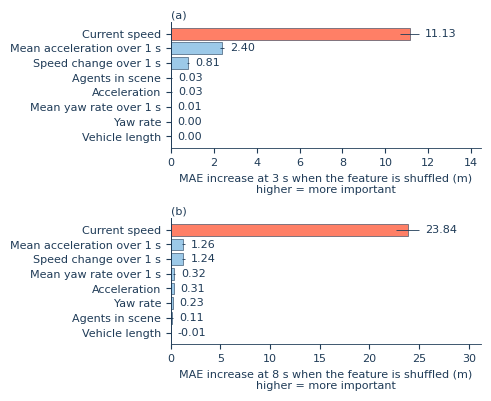

saved report/D/fig_permutation_importance.png


In [25]:
# Permutation importance of Notebook B's selected models (MAE increase on the test set when one feature is shuffled)
from sklearn.inspection import permutation_importance
imp_rows = []
for h in HORIZONS:
    pi = permutation_importance(best_by_h[h], Xte, test[TARGET[h]], scoring=mae_scorer, n_repeats=20, random_state=0, n_jobs=1)
    for f, m, s in zip(X_COLS, pi.importances_mean, pi.importances_std):
        imp_rows.append({"horizon": h, "model": B_SELECTED[h], "feature": f, "MAE_increase": m, "MAE_increase_sd": s})
imp = pd.DataFrame(imp_rows)
imp["rank"] = imp.groupby("horizon")["MAE_increase"].rank(ascending=False, method="min")
imp.to_csv(f"{OUT}/table_permutation_importance.csv", index=False)
display(imp.sort_values(["horizon", "rank"]).round(4))
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 3.9))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    d = imp[imp["horizon"] == h].sort_values("MAE_increase").reset_index(drop=True)
    cols = [C_ACCENT if i == len(d) - 1 else C_BASE for i in range(len(d))]
    ax.barh(
        range(len(d)),
        d["MAE_increase"],
        color=cols,
        edgecolor=C_TEXT,
        linewidth=0.4,
        xerr=d["MAE_increase_sd"],
        error_kw={"elinewidth": 0.6, "ecolor": C_TEXT},
    )
    xmax = (d["MAE_increase"] + d["MAE_increase_sd"]).max() * 1.25
    for i, (v, s) in enumerate(zip(d["MAE_increase"], d["MAE_increase_sd"])):
        ax.text(max(v + s, 0) + 0.02 * xmax, i, f"{v:.2f}", va="center")
    ax.axvline(0, color=C_TEXT, lw=0.6)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([NICE[f] for f in d["feature"]])
    ax.set_xlim(min(0, d["MAE_increase"].min() * 1.2), xmax)
    ax.set_xlabel(f"MAE increase at {h[0]} s when the feature is shuffled (m)\nhigher = more important")
    panel(ax, lab)
fig.tight_layout(pad=0.4, h_pad=1.0)
save_fig(fig, "fig_permutation_importance")

In [26]:
# Agreement between permutation importance (Notebook D) and SHAP shares (Notebook B)
from scipy.stats import spearmanr
agree_rows = []
for h in HORIZONS:
    a = imp[imp["horizon"] == h].set_index("feature")["MAE_increase"]
    b = B["shap"][B["shap"]["horizon"] == h].set_index("feature")["mean"].reindex(a.index)
    agree_rows.append(
        {
            "horizon": h,
            "model": B_SELECTED[h],
            "top_permutation_D": NICE[a.idxmax()],
            "top_SHAP_B": NICE[b.idxmax()],
            "same_top_feature": a.idxmax() == b.idxmax(),
            "spearman_rho": spearmanr(a, b).correlation,
        }
    )
agree = pd.DataFrame(agree_rows)
agree.to_csv(f"{OUT}/table_importance_agreement.csv", index=False)
display(agree.round(3))

,horizon,model,top_permutation_D,top_SHAP_B,same_top_feature,spearman_rho
0,3s,Ridge,Current speed,Current speed,True,0.952
1,8s,Random Forest,Current speed,Current speed,True,0.762


## Bảng kiểm tra chéo với Notebook_B

Mỗi dòng là một con số hoặc kết luận chính của B, đặt cạnh giá trị tính lại ở D:
- **reproduction**: tính lại từ cùng dữ liệu, cùng cách chia, cùng seed → phải `match`;
- **sensitivity**: cách làm khác (tham số mặc định, 5-fold, cách chia calibration khác, mô hình cảnh báo khác, permutation importance) → số được phép khác, cột `status` cho biết kết luận của B có giữ nguyên không.

Bài báo chỉ trích số của Notebook_B; Notebook_D dùng để viết một câu về độ tin cậy, ví dụ “an independent re-implementation reproduces every reported number, and the conclusions hold under default settings and 5-fold grouped cross-validation”.

In [27]:
# Cross-check table: key numbers and conclusions of Notebook B next to Notebook D
xrows = []
def rep_row(item, b, d, tol=TOL):
    xrows.append(
        {
            "item": item,
            "type": "reproduction",
            "Notebook_B": b,
            "Notebook_D": d,
            "abs_diff": abs(d - b),
            "status": "match" if close(d, b, tol) else "DIFFERS",
        }
    )
def sens_row(item, b, d, same):
    xrows.append(
        {
            "item": item,
            "type": "sensitivity",
            "Notebook_B": b,
            "Notebook_D": d,
            "abs_diff": abs(d - b) if np.isscalar(b) and not isinstance(b, str) else np.nan,
            "status": "same conclusion" if same else "CONCLUSION CHANGES",
        }
    )
rep_row("test vehicles", int(B["split"].query("part == 'test'")["vehicles"].iloc[0]), int(split_tab.query("part == 'test'")["vehicles"].iloc[0]))
for r in baseline_table.itertuples():
    rep_row(f"{r.horizon} {r.baseline} MAE (m)", r.MAE_B, r.MAE_D)
for r in tuned.itertuples():
    rep_row(f"{r.horizon} {r.model} (selected) MAE (m)", r.test_MAE_B, r.test_MAE_D)
    rep_row(f"{r.horizon} {r.model} vs constant acceleration (%)", r.dCA_B, r.dCA_D)
for r in chk_motion[chk_motion["method"] == chk_motion["horizon"].map(B_SELECTED)].itertuples():
    rep_row(f"{r.horizon} {r.method} MAE, {r.motion_state} (m)", r.MAE_B, r.MAE)
for r in rep.itertuples():
    rep_row(f"{r.horizon} conformal coverage, global", r.coverage_B, r.coverage, COV_TOL)
    rep_row(f"{r.horizon} conformal width clipped (m)", r.width_clipped_B, r.width_clipped)
for r in chk_state[chk_state["group"] == "moving"].itertuples():
    rep_row(f"{r.horizon} conformal coverage by motion state, moving", r.coverage_B, r.coverage, COV_TOL)
for r in hard_table.itertuples():
    rep_row(f"{r.horizon} hard-case threshold (m)", r.threshold_B, r.hard_error_threshold)
bm = B["main_results"].set_index(["horizon", "method"])
for h in HORIZONS:
    sb = bm.loc[(h, B_SELECTED[h])]
    vb = verdict(sb.reduction_vs_CA_CI_low, sb.reduction_vs_CA_CI_high)
    r = cmp_def[(cmp_def["horizon"] == h) & (cmp_def["kind"] == "tabular model")].iloc[0]
    sens_row(
        f"{h} best tabular model vs constant acceleration: tuned {B_SELECTED[h]} (B) vs default {r.method} (D), %",
        sb.reduction_vs_CA_pct,
        r.dCA_pct,
        np.sign(sb.reduction_vs_CA_pct) == np.sign(r.dCA_pct) or vb == "no clear difference",
    )
    f = folds[folds["horizon"] == h]
    sens_row(
        f"{h} {B_SELECTED[h]} vs constant velocity: 70/30 split (B) vs 5-fold mean (D), %",
        sb.reduction_vs_CV_pct,
        f["dCV_pct"].mean(),
        np.sign(sb.reduction_vs_CV_pct) == np.sign(f["dCV_pct"].mean()),
    )
    sens_row(
        f"{h} {B_SELECTED[h]} vs constant acceleration: 70/30 split (B) vs 5-fold mean (D), %",
        sb.reduction_vs_CA_pct,
        f["dCA_pct"].mean(),
        np.sign(sb.reduction_vs_CA_pct) == np.sign(f["dCA_pct"].mean()) or vb == "no clear difference",
    )
    sens_row(f"{h} family choice by train-only CV: tuned (B) vs default settings (D)", B_SELECTED[h], D_SELECTED[h], B_SELECTED[h] == D_SELECTED[h])
    st = conf_stab[(conf_stab["horizon"] == h) & (conf_stab["quantile_rule"] == "standard (k-th residual)")]
    cb = bglob.loc[h, "coverage"]
    sens_row(
        f"{h} global conformal coverage: B vs mean of 5 other calibration splits (D)",
        cb,
        st["coverage"].mean(),
        abs(st["coverage"].mean() - (1 - ALPHA)) < 0.05,
    )
    mb = B["conformal"].query("horizon == @h and method == 'global' and group == 'moving'")["coverage"].iloc[0]
    sens_row(
        f"{h} global conformal coverage of moving vehicles: B vs mean of 5 other calibration splits (D)",
        mb,
        st["coverage_moving"].mean(),
        (mb < 1 - ALPHA) == (st["coverage_moving"].mean() < 1 - ALPHA),
    )
    w_clf = B["warning"].query("horizon == @h and warner == 'LightGBM warning classifier'")["F1"].iloc[0]
    w_rule = B["warning"][(B["warning"]["horizon"] == h) & B["warning"]["warner"].str.contains("tuned")]["F1"].iloc[0]
    w_d = wd.query("horizon == @h")["F1"].iloc[0]
    sens_row(
        f"{h} warning F1: LightGBM (B) vs logistic regression (D); tuned speed rule F1 = {w_rule:.3f}",
        w_clf,
        w_d,
        w_d - w_rule < 0.05 and w_clf - w_rule < 0.05,
    )  # conclusion of B: no learned warner clearly beats the speed rule
    g = agree[agree["horizon"] == h].iloc[0]
    sens_row(f"{h} top feature: SHAP (B) vs permutation (D)", g.top_SHAP_B, g.top_permutation_D, bool(g.same_top_feature))
crosscheck = pd.DataFrame(xrows)
crosscheck.to_csv(f"{OUT}/table_crosscheck_B.csv", index=False)
with pd.option_context("display.max_colwidth", 120, "display.width", 220):
    display(crosscheck.round(4))
n_rep = (crosscheck["type"] == "reproduction").sum()
n_ok = (crosscheck["status"] == "match").sum()
n_sens = (crosscheck["type"] == "sensitivity").sum()
n_same = (crosscheck["status"] == "same conclusion").sum()
print(f"reproduction: {n_ok}/{n_rep} match | sensitivity: {n_same}/{n_sens} keep Notebook B's conclusion")

,item,type,Notebook_B,Notebook_D,abs_diff,status
0,test vehicles,reproduction,355,355,0.0000,match
1,3s Constant velocity MAE (m),reproduction,1.370148,1.370148,0.0000,match
2,3s Constant acceleration MAE (m),reproduction,0.966658,0.966658,0.0000,match
3,3s CTRV MAE (m),reproduction,1.381015,1.381015,0.0000,match
4,8s Constant velocity MAE (m),reproduction,8.755057,8.755057,0.0000,match
5,8s Constant acceleration MAE (m),reproduction,7.925851,7.925851,0.0000,match
6,8s CTRV MAE (m),reproduction,8.899147,8.899147,0.0000,match
7,3s Ridge (selected) MAE (m),reproduction,1.140767,1.140767,0.0000,match
8,3s Ridge vs constant acceleration (%),reproduction,-18.011469,-18.011469,0.0000,match
9,8s Random Forest (selected) MAE (m),reproduction,6.97949,6.97949,0.0000,match


reproduction: 23/23 match | sensitivity: 16/16 keep Notebook B's conclusion


In [28]:
# Final tests for Notebook D: structural validity, leakage safety, reproduction of Notebook B and saved outputs
assert set(train["scenario"]).isdisjoint(set(test["scenario"])), "scenario leakage"
assert set(train[UNIT_COL]).isdisjoint(set(test[UNIT_COL])), "vehicle leakage"
for h in HORIZONS:
    assert test[TARGET[h]].notna().all() and test[X_COLS].notna().all().all(), f"{h}: missing test values"
assert not any(c.startswith("y_") for c in X_COLS + MOTION_VIEW), "target column used as a feature"
assert "chronos" not in sys.modules, "Chronos must not be used"
required_files = [
    "table_split",
    "table_rq2_baseline",
    "table_rq2_summary",
    "table_rq2_default_vs_tuned",
    "table_rq2_family_selection_cv",
    "table_rq2_tuning",
    "table_rq2_error_by_density",
    "table_rq2_folds",
    "table_rq2_per_vehicle_quantiles",
    "table_rq3_conformal",
    "table_rq3_conformal_cal_splits",
    "table_rq3_conformal_state",
    "table_rq3_hardcase_thresholds",
    "table_rq3_warning",
    "table_rq3_warning_diagnostics",
    "table_rq3_ablation",
    "table_permutation_importance",
    "table_importance_agreement",
    "table_crosscheck_B",
]
for f in required_files:
    assert os.path.exists(f"{OUT}/{f}.csv"), f"missing {OUT}/{f}.csv"
for f in ["fig_rq2_models", "fig_rq2_error_by_density", "fig_permutation_importance"]:
    assert os.path.exists(f"{OUT}/{f}.png"), f"missing {OUT}/{f}.png"
assert ((conf["coverage"] >= 0) & (conf["coverage"] <= 1)).all() and (conf["width_clipped"] >= 0).all()
for col in ["hard_rate", "warning_rate", "ROC_AUC", "PR_AUC", "precision", "recall", "F1"]:
    assert warning_table[col].between(0, 1).all(), f"invalid {col}"
assert np.isfinite(abl[["motion_only_MAE", "motion_context_MAE"]]).all().all()
assert (crosscheck.loc[crosscheck["type"] == "reproduction", "status"] == "match").all(), "some Notebook B numbers were not reproduced"
print("Tests D: OK")

Tests D: OK


In [29]:
# Save the refitted Notebook B models for both horizons
bundle = {
    "models": best_by_h,
    "model_names": B_SELECTED,
    "feature_cols": X_COLS,
    "targets": TARGET,
    "horizon_seconds": HORIZONS,
    "best_params": {h: PARAMS[(h, B_SELECTED[h])] for h in HORIZONS},
    "clip_predictions_at_zero": True,
    "dataset": "Waymo Open Motion Dataset v1.2",
}
with open(f"{OUT}/best_models_by_horizon.pkl", "wb") as f:
    pickle.dump(bundle, f)
with open(f"{OUT}/best_models_by_horizon.pkl", "rb") as f:
    check_bundle = pickle.load(f)
assert set(check_bundle["models"]) == set(HORIZONS)
print(f"saved {OUT}/best_models_by_horizon.pkl | models:", check_bundle["model_names"])

saved report/D/best_models_by_horizon.pkl | models: {'3s': 'Ridge', '8s': 'Random Forest'}


## Bài tập mở rộng cho Sinh viên B

Các bài mở rộng là **optional** sau khi phần kiểm tra chéo đã chạy qua. Nếu làm, ghi vào `report/D/exercises_D.md`.

1. ExtraTrees trong cùng giao thức chia theo cảnh, cả 3 s và 8 s;
2. quantile LightGBM so với split conformal;
3. reliability diagram cho bộ cảnh báo;
4. ngưỡng cảnh báo theo chi phí.

Bài tập mô hình riêng cho từng xe đã bỏ: bảng step 10 chỉ có một dòng mỗi xe. Không gọi feature view phụ là một nguồn dữ liệu độc lập.

In [30]:
# Exercise 1: ExtraTrees under the same scenario-disjoint protocol (both horizons, 5 seeds)
from sklearn.ensemble import ExtraTreesRegressor
extra_rows = []
for h in HORIZONS:
    for seed in SEEDS:
        p = np.clip(
            ExtraTreesRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed).fit(Xtr, train[TARGET[h]]).predict(Xte), 0, None
        )
        extra_rows.append(
            {
                "model": "ExtraTrees",
                "horizon": h,
                "seed": seed,
                **metrics(test[TARGET[h]], p, PHYS[h]["Constant velocity"], PHYS[h]["Constant acceleration"]),
            }
        )
extra_table = pd.DataFrame(extra_rows)
display(extra_table.groupby("horizon")[["MAE", "RMSE", "dCV_pct", "dCA_pct"]].agg(["mean", "std"]).round(3))

MAE           RMSE        dCV_pct        dCA_pct       
          mean    std    mean    std    mean    std    mean    std
horizon                                                           
3s       0.992  0.004   1.948  0.006  27.631  0.268  -2.577  0.379
8s       6.910  0.030  12.757  0.043  21.075  0.340  12.817  0.375

In [31]:
# Exercise 2: quantile LightGBM vs split conformal on the 3 s horizon (coverage and width together)
q_lo = np.clip(
    LGBMRegressor(objective="quantile", alpha=0.05, n_estimators=600, learning_rate=0.03, random_state=0, verbose=-1).fit(Xtr, y_tr).predict(Xte),
    0,
    None,
)
q_hi = LGBMRegressor(objective="quantile", alpha=0.95, n_estimators=600, learning_rate=0.03, random_state=0, verbose=-1).fit(Xtr, y_tr).predict(Xte)
quantile_cov = ((y_te.to_numpy() >= q_lo) & (y_te.to_numpy() <= q_hi)).mean()
c3 = conf[(conf["horizon"] == "3s") & (conf["quantile_rule"] == "standard (k-th residual)")].iloc[0]
print(
    "quantile LightGBM coverage:",
    round(float(quantile_cov), 3),
    "| mean width:",
    round(float(np.mean(q_hi - q_lo)), 3),
    "| split conformal coverage:",
    round(float(c3.coverage), 3),
    "| mean width (clipped):",
    round(float(c3.width_clipped), 3),
)

quantile LightGBM coverage: 0.823 | mean width: 3.698 | split conformal coverage: 0.893 | mean width (clipped): 4.783


3s ECE: 0.2676
8s ECE: 0.2441


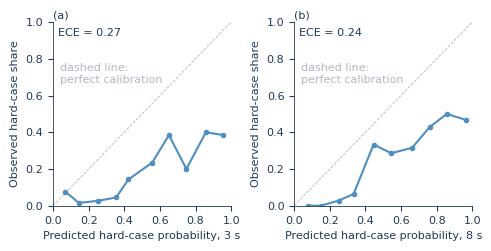

saved report/D/fig_exercise_calibration.png


In [32]:
# Exercise 3: reliability diagram and ECE of the logistic-regression warner at both horizons
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.4))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    p, y = warning_by_h[h]["p_test"], warning_by_h[h]["hard"].astype(int)
    frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="uniform")
    bins = np.minimum((p * 10).astype(int), 9)
    ece = sum((bins == k).mean() * abs(y[bins == k].mean() - p[bins == k].mean()) for k in range(10) if (bins == k).any())
    ax.plot([0, 1], [0, 1], ls="--", lw=0.6, color=C_GREY)
    ax.text(0.04, 0.66, "dashed line:\nperfect calibration", color=C_GREY, ha="left", va="bottom")
    ax.plot(mean_p, frac, marker="o", ms=3, color=C_MID)
    ax.text(0.03, 0.97, f"ECE = {ece:.2f}", transform=ax.transAxes, va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(f"Predicted hard-case probability, {h[0]} s")
    ax.set_ylabel("Observed hard-case share")
    panel(ax, lab)
    print(h, "ECE:", round(float(ece), 4))
fig.tight_layout(pad=0.4, w_pad=1.0)
save_fig(fig, "fig_exercise_calibration")

In [33]:
# Exercise 4: cost-sensitive threshold; a missed hard case costs 5x a false warning
for h in HORIZONS:
    p, y = warning_by_h[h]["p_test"], warning_by_h[h]["hard"].astype(int)
    costs = [(t, 5 * ((p < t) & (y == 1)).sum() + ((p >= t) & (y == 0)).sum()) for t in np.linspace(0.05, 0.95, 19)]
    t_best, c_best = min(costs, key=lambda x: x[1])
    print(f"{h}: cost-minimising threshold {t_best:.2f} | cost {int(c_best)}")

3s: cost-minimising threshold 0.45 | cost 120
8s: cost-minimising threshold 0.40 | cost 89


### Tự đánh giá Notebook_D

| Tiêu chí | Tự chấm (0–2) | Bằng chứng |
|---|---:|---|
| Cùng bảng step 10, cùng cách chia với B | | `report/D/table_split.csv` |
| Ba mốc vật lý tái lập đúng số của B | | `report/D/table_rq2_baseline.csv` |
| Mô hình được chọn tái lập đúng MAE của B | | `report/D/table_rq2_tuning.csv` |
| Tham số mặc định và 5-fold không đổi kết luận | | `table_rq2_default_vs_tuned.csv`, `table_rq2_folds.csv` |
| Conformal: coverage + width, theo trạng thái, 5 cách chia calibration | | `table_rq3_conformal*.csv` |
| Bộ cảnh báo thứ hai so với B và quy tắc tốc độ | | `table_rq3_warning.csv` |
| Feature-view ablation cùng WOMD v1.2 | | `table_rq3_ablation.csv` |
| Permutation importance so với SHAP của B | | `table_importance_agreement.csv` |
| Bảng kiểm tra chéo | | `table_crosscheck_B.csv` |
| Test cases | | `Tests D: OK` |
| AI Audit Log | | sửa/chốt sau khi kết quả thật đã được kiểm tra |

## Lỗi thường gặp và cách sửa

| Lỗi | Nguyên nhân | Cách sửa |
|---|---|---|
| `run Notebook B first, missing: ...` | chưa chạy Notebook_B hoặc B lưu vào chỗ khác | chạy Notebook_B (Restart & Run All) rồi chạy lại D |
| `split differs from Notebook B` | đổi seed, tỉ lệ test hoặc bảng đầu vào | giữ `SPLIT_SEED = 42`, `TEST_FRAC = 0.30`, đọc bảng từ `manifest.json` |
| `selected model does not reproduce ...` | B đã chạy lại với tham số khác hoặc phiên bản thư viện khác | chạy lại B rồi D trên cùng máy, cùng kernel |
| 3 s và 8 s khác số xe | dùng bảng nhiều step thay cho bảng step 10 | dùng `feat_core_origin10.parquet` |
| File của B bị ghi đè | lưu vào `report/` | mọi output của D lưu vào `report/D/` |
| Coverage cao nhưng vô ích | khoảng quá rộng | luôn báo coverage cùng độ rộng, cắt và chưa cắt |
| Bộ cảnh báo quá đẹp | chọn ngưỡng trên test | chọn ngưỡng trên dự đoán out-of-fold của train |
| Ablation bị gọi là “second source” | hai view thực chất cùng WOMD v1.2 | gọi là feature-view ablation |

## Checklist Notebook_D trước khi viết bài

- [ ] `handover OK`, MD5 khớp `origin_md5`
- [ ] cách chia trùng `table_split.csv` của B
- [ ] ba mốc vật lý và mô hình được chọn tái lập đúng số của B
- [ ] tham số mặc định và 5-fold: kết luận của B giữ nguyên hay không (ghi thật)
- [ ] conformal: coverage và độ rộng ở cả hai horizon, theo trạng thái, qua 5 cách chia calibration
- [ ] bộ cảnh báo thứ hai so với LightGBM của B và quy tắc tốc độ
- [ ] permutation importance so với SHAP của B
- [ ] `table_crosscheck_B.csv`: mọi dòng reproduction là `match`
- [ ] `Tests D: OK`
- [ ] Audit Log sửa/chốt sau khi toàn bộ output thật đã kiểm tra

## Mẫu viết sau khi chạy xong

**Trong bài báo** chỉ trích số của Notebook_B. Notebook_D được nhắc ở phần Method hoặc Threats to validity bằng một hai câu, lấy từ `report/D/table_crosscheck_B.csv`:

- **Tái lập**: “An independent re-implementation of the baselines, the selected models, the conformal intervals and the hard-case threshold reproduces all reported values.”
- **Độ nhạy**: nói rõ kết luận nào giữ khi dùng tham số mặc định, 5-fold theo cảnh và 5 cách chia calibration; nếu một kết luận đổi thì ghi thẳng.
- **Cảnh báo**: F1 của logistic regression so với LightGBM của B và quy tắc tốc độ. Nếu cả hai bộ phân loại chỉ ngang quy tắc tốc độ, nói đúng như vậy.
- **Biến quan trọng**: permutation importance và SHAP có cùng biến đứng đầu không.

Không trình bày D như kết quả thứ hai độc lập; nó dùng cùng dữ liệu, cùng cách chia với B.